# Análise exploratória

In [1]:
#importando Pandas e carregamento do dataset

import pandas as pd
dataset = pd.read_csv("london_houses.csv")
dataset

,Address,Neighborhood,Bedrooms,Bathrooms,Square Meters,Building Age,Garden,Garage,Floors,Property Type,Heating Type,Balcony,Interior Style,View,Materials,Building Status,Price (£)
0,78 Regent Street,Notting Hill,2,3,179,72,No,No,3,Semi-Detached,Electric Heating,High-level Balcony,Industrial,Garden,Marble,Renovated,2291200
1,198 Oxford Street,Westminster,2,1,123,34,Yes,No,1,Apartment,Central Heating,High-level Balcony,Industrial,City,Laminate Flooring,Old,1476000
2,18 Regent Street,Soho,5,3,168,38,No,Yes,3,Semi-Detached,Central Heating,No Balcony,Industrial,Street,Wood,Renovated,1881600
3,39 Piccadilly Circus,Islington,5,1,237,53,Yes,Yes,1,Apartment,Underfloor Heating,No Balcony,Classic,Park,Granite,Renovated,1896000
4,116 Fleet Street,Marylebone,4,1,127,23,No,Yes,2,Semi-Detached,Central Heating,No Balcony,Modern,Park,Wood,Old,1524000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,44 Camden High Street,Westminster,1,3,81,4,Yes,Yes,2,Semi-Detached,Central Heating,Low-level Balcony,Modern,Street,Laminate Flooring,Renovated,1166400
996,165 Park Lane,Camden,1,1,65,51,No,No,1,Apartment,Underfloor Heating,No Balcony,Industrial,Garden,Wood,Old,563333
997,99 Camden High Street,Camden,4,1,191,27,No,Yes,2,Semi-Detached,Central Heating,Low-level Balcony,Minimalist,Park,Laminate Flooring,Old,1986399
998,155 Park Lane,Camden,5,2,131,3,Yes,No,2,Detached House,Underfloor Heating,High-level Balcony,Modern,Park,Laminate Flooring,Renovated,1703000


In [27]:
#verificando tamanho do dataset
dataset.shape

(1000, 17)

In [3]:
#verificando valores nulos 
dataset.isnull().sum()

Address            0
Neighborhood       0
Bedrooms           0
Bathrooms          0
Square Meters      0
Building Age       0
Garden             0
Garage             0
Floors             0
Property Type      0
Heating Type       0
Balcony            0
Interior Style     0
View               0
Materials          0
Building Status    0
Price (£)          0
dtype: int64

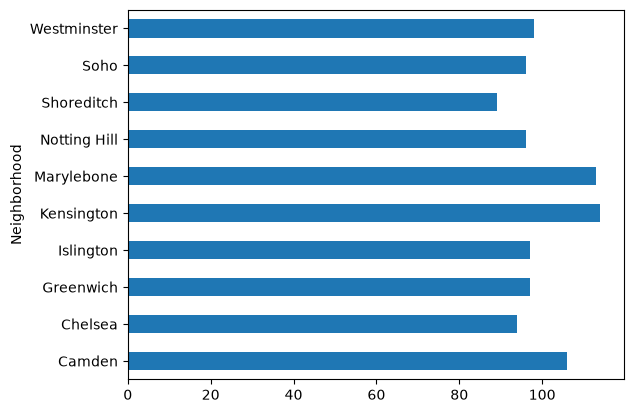

In [4]:
#verificando informações das colunas

dataset.groupby('Neighborhood')['Neighborhood'].count().plot.barh();
#dataset.groupby('Property Type')['Property Type'].count().plot.barh();
#dataset.groupby('Heating Type')['Heating Type'].count().plot.barh();
#dataset.groupby('Balcony')['Balcony'].count().plot.barh();
#dataset.groupby('Interior Style')['Interior Style'].count().plot.barh();
#dataset.groupby('View')['View'].count().plot.barh();
#dataset.groupby('Materials')['Materials'].count().plot.barh();
#dataset.groupby('Building Status')['Building Status'].count().plot.barh();

In [ ]:
#Verificando se existem valores duplicados no dataset
dataset.duplicated().sum()

np.int64(0)

# Feature Engineer - XGBoost

In [6]:
#Separando as variáveis independentes e dependentes

X = dataset[["Address", "Bedrooms", "Bathrooms", "Square Meters", "Building Age", 
             "Garden", "Garage", "Property Type", "Balcony", "Interior Style", "View", "Building Status"]]
y = dataset["Price (£)"]

categorical_cols = ["Address", "Garden", "Garage", "Property Type", "Balcony",
                    "Interior Style", "View", "Building Status"]

In [7]:
#Importando as bibliotecas necessárias

from xgboost import XGBRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [8]:
#Transformando as variáveis categóricas em variáveis numéricas usando OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'  
)

X_transformed = preprocessor.fit_transform(X)

In [9]:
#Separando os dados em conjuntos de treino e teste
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_transformed, y, test_size=0.2, random_state=42
)

In [10]:
#Aplicando o modelo XGBoost para regressão

xgb_model = XGBRegressor(
    n_estimators=100,                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                
    learning_rate=0.1,      
    max_depth=5,            
    random_state=42
)
xgb_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [11]:
#Utilizando dados de teste

y_pred = xgb_model.predict(X_test)

In [ ]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_percentage_error,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

smape = np.mean(2 * np.abs(y_pred - y_test) / (np.abs(y_test) + np.abs(y_pred))) * 100
mape = mean_absolute_percentage_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("SMAPE:", smape)
print("MAPE:", mape)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)


SMAPE: 19.273004829706995
MAPE: 0.198892742395401
MAE: 356372.15625
MSE: 214257958912.0
RMSE: 462880.0696854424
R²: 0.7340234518051147


In [13]:
#Fazendo previsão com novos dados de casa

nova_casa = pd.DataFrame({
    "Address": ["Camden"],
    "Bedrooms": [3],
    "Bathrooms": [2],
    "Square Meters": [120],
    "Building Age": [10],
    "Garden": ["Yes"],
    "Garage": ["No"],
    "Property Type": ["Detached"],
    "Balcony": ["No"],
    "Interior Style": ["Modern"],
    "View": ["City"],
    "Building Status": ["New"]
})

nova_casa_transformed = preprocessor.transform(nova_casa)
preco_estimado = xgb_model.predict(nova_casa_transformed)
print(f"Preço estimado da casa: £ {preco_estimado[0]:,.2f}")


Preço estimado da casa: £ 1,534,109.50


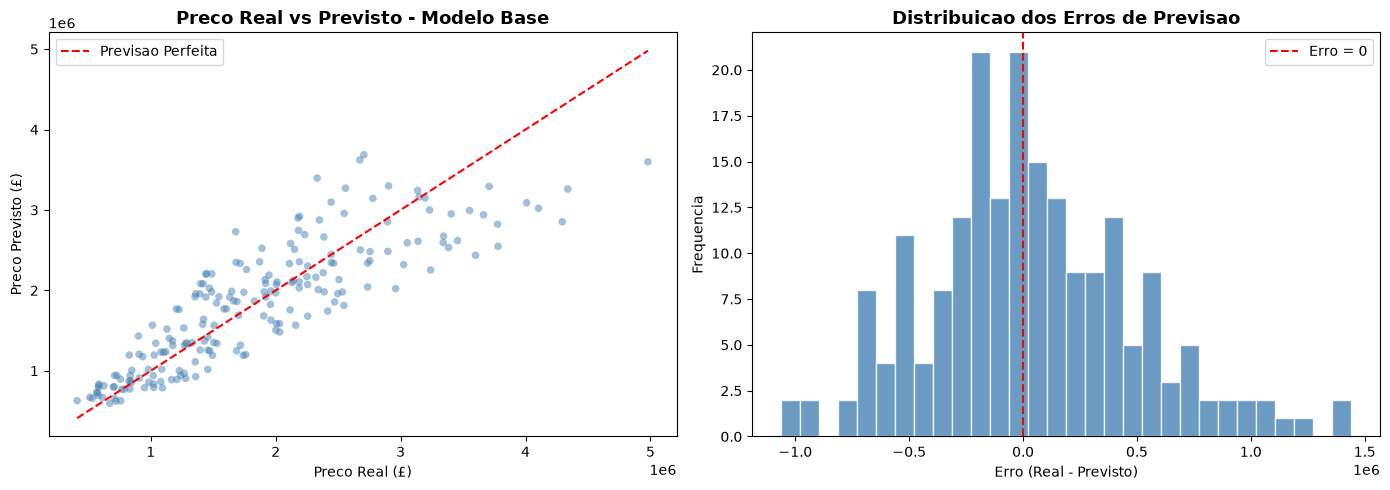

In [ ]:
#Gráfico para comparação

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#Scatter real vs previsto
axes[0].scatter(y_test, y_pred, alpha=0.5, color='steelblue', edgecolors='none', s=30)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', label='Previsao Perfeita')
axes[0].set_title('Preco Real vs Previsto - Modelo Base', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Preco Real (£)')
axes[0].set_ylabel('Preco Previsto (£)')
axes[0].legend()

#Distribuicao dos erros
erros = y_test.values - y_pred
axes[1].hist(erros, bins=30, color='steelblue', edgecolor='white', alpha=0.8)
axes[1].axvline(0, color='red', linestyle='--', label='Erro = 0')
axes[1].set_title('Distribuicao dos Erros de Previsao', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Erro (Real - Previsto)')
axes[1].set_ylabel('Frequencia')
axes[1].legend()

plt.tight_layout()
plt.show()

# Aplicando técnica de Validação cruzada com vários folds e randomized search

In [ ]:
#Importando as bibliotecas necessárias

from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.metrics import mean_absolute_percentage_error, make_scorer

In [16]:
#Separando dados em variáveis independentes e dependentes
X = dataset[["Address", "Bedrooms", "Bathrooms", "Square Meters", "Building Age", 
             "Garden", "Garage", "Property Type", "Balcony", "Interior Style", "View", "Building Status"]]
y = dataset["Price (£)"]

categorical_cols = ["Address", "Garden", "Garage", "Property Type", "Balcony",
                    "Interior Style", "View", "Building Status"]

In [17]:
#Pré processamento das variáveis categóricas usando OneHotEncoder
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'
)

X_transformed = preprocessor.fit_transform(X)

In [18]:
#Separando os dados em conjuntos de treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X_transformed, y, test_size=0.2, random_state=42
)

In [19]:
#Métrica SMAPE
def smape(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    denom = np.abs(y_true) + np.abs(y_pred)
    denom = np.where(denom==0, 1e-8, denom)
    return 100 * np.mean(2 * np.abs(y_pred - y_true) / denom)


In [20]:
#Configurando Randomized Search 
mape_scorer = make_scorer(mean_absolute_percentage_error, greater_is_better=False)

param_dist = {
    'n_estimators': [50, 100, 200, 500],
    'max_depth': [3, 5, 10],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'reg_alpha': [0, 0.01, 0.1],
    'reg_lambda': [1, 5, 10]
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

rs = RandomizedSearchCV(
    estimator=XGBRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=20,               #número de combinações aleatórias
    scoring=mape_scorer,
    cv=cv,
    n_jobs=-1,
    verbose=2
)


In [21]:
#Treinando o modelo com Randomized Search
rs.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.8, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",make_scorer(m...hod='predict')
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made av

In [22]:
#Melhor modelo encontrado
best_model = rs.best_estimator_

In [23]:
#Aplicando a previsão nos dados de treino e teste
y_train_pred = best_model.predict(X_train)
y_test_pred  = best_model.predict(X_test)

In [24]:
#Calculando as métricas
mape_train = mean_absolute_percentage_error(y_train, y_train_pred) * 100
mape_test  = mean_absolute_percentage_error(y_test, y_test_pred) * 100
smape_train = smape(y_train, y_train_pred)
smape_test  = smape(y_test, y_test_pred)

In [25]:
#Exibindo os resultados
print("Melhor combinação de hiperparâmetros:", rs.best_params_)
print(f"MAPE train:  {mape_train:.3f} %")
print(f"MAPE test:   {mape_test:.3f} %")
print(f"SMAPE train: {smape_train:.3f} %")
print(f"SMAPE test:  {smape_test:.3f} %")

Melhor combinação de hiperparâmetros: {'subsample': 1.0, 'reg_lambda': 5, 'reg_alpha': 0, 'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
MAPE train:  17.208 %
MAPE test:   19.948 %
SMAPE train: 16.416 %
SMAPE test:  19.180 %


In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_rs  = mean_absolute_error(y_test, y_test_pred)
rmse_rs = np.sqrt(mean_squared_error(y_test, y_test_pred))
r2_rs   = r2_score(y_test, y_test_pred)

print('=== COMPARACAO DE MODELOS ===')
print()
print(f'{"Metrica":<10} {"Modelo Base":>15} {"RandomizedSearch":>18}')
print('-' * 45)
print(f'{"MAPE":<10} {"19.89%":>15} {f"{mape_test:.2f}%":>18}')
print(f'{"SMAPE":<10} {"19.27%":>15} {f"{smape_test:.2f}%":>18}')
print(f'{"MAE":<10} {"£356,372":>15} {f"£{mae_rs:,.0f}":>18}')
print(f'{"RMSE":<10} {"£462,880":>15} {f"£{rmse_rs:,.0f}":>18}')
print(f'{"R2":<10} {"0.734":>15} {f"{r2_rs:.3f}":>18}')

=== COMPARACAO DE MODELOS ===

Metrica        Modelo Base   RandomizedSearch
---------------------------------------------
MAPE                19.89%             19.95%
SMAPE               19.27%             19.18%
MAE               £356,372           £355,061
RMSE              £462,880           £460,407
R2                   0.734              0.737


# Conclusão

Este notebook treinou e avaliou um modelo **XGBoost Regressor** para prever o preço
de imóveis em Londres com base em 12 características como localização, metragem,
número de quartos, jardim, garagem e estilo de interiores.

O objetivo principal foi estudar o funcionamento do XGBoost e seus parametros,
como taxa de aprendizado, profundidade maxima das arvores e regularizacao.
O RandomizedSearch foi adicionado como estudo complementar para entender a
otimizacao de hiperparametros em modelos de Gradient Boosting.

## Comparação de Resultados

| Metrica | Modelo Base | RandomizedSearch |
|---------|------------|-----------------|
| MAPE    | 19.89%     | 19.95%          |
| SMAPE   | 19.27%     | 19.18%          |
| MAE     | £356,372   | £355,061        |
| RMSE    | £462,880   | £460,407        |
| R2      | 0.734      | 0.737           |

## Interpretação

O modelo base atingiu um R2 de 0.734, explicando 73.4% da variação nos preços
dos imóveis. O erro medio absoluto de £356,372 em imóveis com preços entre
£500k e £2.5M representa um erro de aproximadamente 19-20%, esperado para
um dataset com alta variabilidade de preços em diferentes bairros de Londres.

O RandomizedSearch testou 20 combinacoes aleatórias de hiperparametros com
validação cruzada de 5 folds, encontrando como melhor configuração:
n_estimators=500, max_depth=3, learning_rate=0.05, subsample=1.0,
colsample_bytree=1.0, reg_alpha=0, reg_lambda=5.

Os dois modelos apresentaram resultados muito proximos, com o RandomizedSearch
entregando uma melhora marginal em MAE (£355,061 vs £356,372), RMSE
(£460,407 vs £462,880) e R2 (0.737 vs 0.734). Isso indica que o modelo base
ja estava bem configurado para esse dataset, e que aumentar n_iter no
RandomizedSearch poderia explorar melhor o espaco de parâmetros e encontrar
uma combinação mais expressivamente superior.